# Phase 4 — $n{=}40$ vs. full-suite HumanEval-TS, figure

Figure for `sec:phase4-full-suite-noise` in `docs/latex/main.tex`: every one of the
five candidates re-evaluated on the full 159-problem suite scored lower than its
$n{=}40$ sample score, by an inconsistent margin. Loads the already-committed
`docs/debug/*_run_summary.json` ($n{=}40$, `humaneval_best_pass_at_1`) and
`docs/debug/*_humaneval_ts_full.json` (full-suite `pass@1`) for each candidate —
no GPU needed, this just plots results already measured and archived elsewhere.


In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")

CANDIDATES = [
    ("d16/e80", "phase4_aggressive_depth_experts_fixedloss_short"),
    ("d0/e97", "phase4_depth0_experts97_fixedloss_short"),
    ("d12/e80", "phase4_depth12_experts80_rawfile_fixedloss"),
    ("d22/e92", "phase4_depth22_experts92_fixedloss_short"),
    ("d0/e60", "phase4_depth0_experts60_fixedloss_short"),
]

labels, n40, full = [], [], []
for label, prefix in CANDIDATES:
    summary = json.loads((DEBUG / f"{prefix}_run_summary.json").read_text())
    metrics = json.loads((DEBUG / f"{prefix}_humaneval_ts_full.json").read_text())
    assert metrics["config"]["limit"] is None, (label, metrics["config"]["limit"])
    labels.append(label)
    n40.append(summary["humaneval_best_pass_at_1"])
    full.append(metrics["multiple-ts"]["pass@1"])

list(zip(labels, n40, full, strict=True))

[('d16/e80', 0.5, 0.20754716981132076),
 ('d0/e97', 0.4, 0.2830188679245283),
 ('d12/e80', 0.55, 0.3018867924528302),
 ('d22/e92', 0.225, 0.06918238993710692),
 ('d0/e60', 0.7, 0.5723270440251572)]

In [2]:
overstatement_pct = [(n - f) / f * 100 for n, f in zip(n40, full, strict=True)]
list(zip(labels, overstatement_pct, strict=True))

[('d16/e80', 140.9090909090909),
 ('d0/e97', 41.33333333333334),
 ('d12/e80', 82.18750000000003),
 ('d22/e92', 225.22727272727275),
 ('d0/e60', 22.307692307692303)]

## The figure

Grouped bars, one pair per candidate — $n{=}40$ sample vs. the full 159-problem
suite. Every candidate's full-suite bar is shorter than its $n{=}40$ bar.


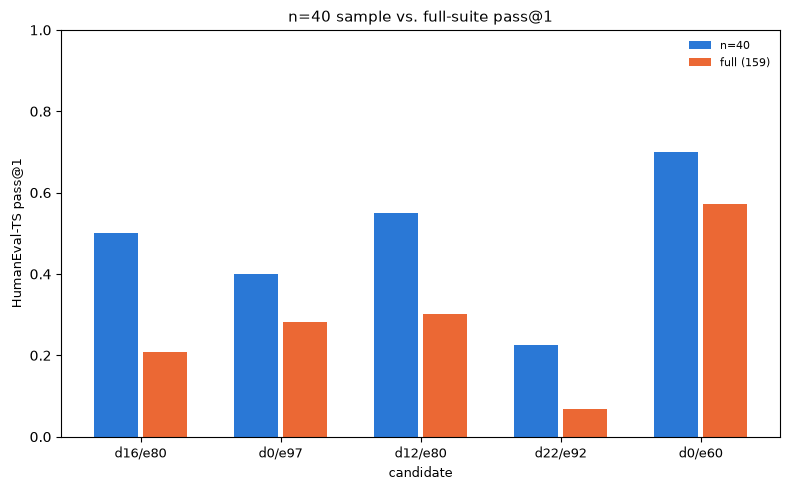

In [3]:
from bonsai.pruning.viz import plot_n40_vs_full_suite

fig = plot_n40_vs_full_suite(labels, n40, full)
fig.savefig("../docs/latex/figures/phase4_n40_vs_full_suite.png", dpi=150)
fig.savefig("../docs/latex/figures/phase4_n40_vs_full_suite.pdf")